# Which funnel stage owns the loss, on which denominator, and for whom?

**Week 4, Thursday, chapter 3 of 3 (L3).** Chapter 2 took the dashboard's flat 38 percent apart:
every cohort falls with age, and the 13,000-member August cohort, whose 8,027 sale-week members
kept 20 percent in month one, is outside the count until October. This notebook turns to the order flow,
where the ticket says something changed on 14 September.

> *Illustrative case: the company is real, the situation and the data are synthetic, built for
> this class.*

**The ticket. Zomato Gold, Chennai, the membership and the app's order flow.** The membership
dashboard reports month-two retention for Chennai, the share of members two or more months past
their signup month who ordered in the month, as flat at 38 percent for June, July, August and
September 2026. Each signup cohort's own curve falls with age, and each cohort's month-one rate is
lower than the one before: January 58 percent, April 53, July 49, and August 31. The August cohort,
13,000 members, 2.6 times the 5,000 a month of January to July, grew out of a sale week with a
discounted first month. On Monday 14 September 2026 a new checkout flow shipped on Android; since
then members' add-to-cart to order conversion on Android fell from 58 to 44 percent, while members
on iOS went from 57 to 56 and non-members on Android from 52 to 51. **The ask, due Friday:** is it
a cohort problem or an everyone problem, which funnel stage owns the loss, and what should be fixed
first, with the evidence.

**Who needs the answer.** The membership lead and the app team's lead, who will say the stage the
room blames is fine. Blaming the wrong stage sends engineers to fix a step that works.

**The questions on the way.**

1. What does each step of the funnel read in September, per session?
2. Why does one step read above 100 percent, and what does it really read?
3. Per session or per member: which unit answers which question?
4. Where did add-to-cart to order fall after 14 September, and for whom?
5. Which step inside the checkout changed, and how many orders a week does it cost?

In [1]:
# Load the event log: one row per stage a session reached, August and September 2026.
import pandas as pd
import matplotlib.pyplot as plt

def check(name, ok):
    print(("PASS  " if ok else "FAIL  ") + name)

ev = pd.read_csv("../data/C2_W04_D04_events_STUDENT.csv.gz", parse_dates=["event_ts"])
print(f"{len(ev):,} events in {ev['session_id'].nunique():,} sessions")
check("no session reaches a stage twice", not ev.duplicated(["session_id", "stage"]).any())

1,386,235 events in 444,218 sessions


PASS  no session reaches a stage twice


## How does a funnel read, on numbers small enough to hold?

A toy (invented): 100 app visits, 40 searches, 20 add-to-carts, 10 checkouts. Each step's rate
divides it by the step before, so 40, 50 and 50 percent, and 10 percent of visits end in a
checkout. If those 10 checkouts came from 50 sessions of 20 people, checkout is 10 of 50 per
session and 10 of 20 per person: the same checkouts, two units, two numbers.

In [2]:
# The toy's step rates, each one over the step before.
toy = pd.Series({"visit": 100, "search": 40, "add_to_cart": 20, "checkout": 10})
print((toy / toy.shift(1)).dropna().map("{:.0%}".format).to_string())
check("the toy: 10 percent of visits end in a checkout", toy["checkout"] / toy["visit"] == 0.10)

search         40%
add_to_cart    50%
checkout       50%
PASS  the toy: 10 percent of visits end in a checkout


## What does each step of the funnel read in September, per session?

Gold members' sessions in September. A session reaches a stage when the log has that row, so
sessions reaching a stage are the stage's row count. **Predict before you run.** Which step reads
above 100 percent?

- a) Open the app to search
- b) Search to menu view
- c) Menu view to add to cart
- d) None: no step can pass 100 percent

In [3]:
# Sessions reaching each stage in September (members), and each step over the step before.
stages = ["open", "search", "menu_view", "add_to_cart", "checkout_start", "order_placed"]
sep = ev[ev["is_member"] & (ev["event_ts"].dt.month == 9)]
per_session = sep["stage"].value_counts().reindex(stages)
steps = pd.DataFrame({"sessions": per_session, "of the step before": (per_session / per_session.shift(1)).round(3)})
steps

,sessions,of the step before
stage,,
open,194211,NaN
search,131974,0.680
menu_view,155729,1.180
add_to_cart,52948,0.340
checkout_start,42358,0.800
order_placed,27212,0.642


**What happened.** The answer is b: 155,729 sessions opened a menu and 131,974 searched, so
search to menu view reads 118 percent. **The plausible wrong answer** is to read that as the best
step in the app, or, worse, to read the 34 percent at menu view to add-to-cart as the loss. **Why
the 118 is wrong.** The home carousel opens a restaurant's menu without a search, so many menu
views come from sessions that never searched: the step is skippable, and the ratio divides two
counts of different sessions. **The fix** counts menu views only among sessions that searched.

In [4]:
# The fix: of the sessions that searched, the share that went on to a menu.
searched = set(sep.loc[sep["stage"] == "search", "session_id"])
menu = set(sep.loc[sep["stage"] == "menu_view", "session_id"])
print(f"sessions that searched and then opened a menu: {len(searched & menu) / len(searched):.1%}")
print(f"menu sessions with no search (the carousel): {len(menu - searched):,}")
check("among sessions that searched, the step reads under 100 percent", len(searched & menu) < len(searched))

sessions that searched and then opened a menu: 88.5%
menu sessions with no search (the carousel): 38,932
PASS  among sessions that searched, the step reads under 100 percent


## Per session or per member: which unit answers which question?

Per session asks how often a visit to a menu turns into a cart; per member asks how many of the
members who looked at a menu ever added to a cart that month. **Predict before you run.** Menu
view to add-to-cart reads 34 percent per session. Per member it reads:

- a) The same, 34 percent
- b) Lower, because members browse many times
- c) Higher, because a member who browses five times and buys once counts once
- d) Above 100 percent

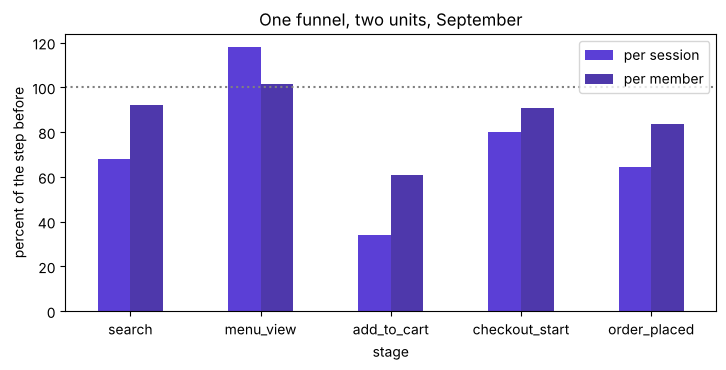

,per session,per member
stage,,
search,68.0,92.1
menu_view,118.0,101.3
add_to_cart,34.0,61.0
checkout_start,80.0,90.8
order_placed,64.2,83.8


In [5]:
# The same September funnel counted in members, and both units drawn side by side.
per_member = sep.groupby("stage")["user_id"].nunique().reindex(stages)
both = pd.DataFrame({"per session": (per_session / per_session.shift(1)),
                     "per member": (per_member / per_member.shift(1))}).dropna()
ax = (100 * both).plot.bar(figsize=(8.4, 3.6), color=["#5B3FD6", "#4E38AB"], rot=0)
ax.axhline(100, ls=":", color="grey"); ax.set_ylabel("percent of the step before")
ax.set_title("One funnel, two units, September"); plt.show()
(100 * both).round(1)

**What happened.** The answer is c: 61 percent per member against 34 per session. Neither is
wrong; each answers a different question, and a chart that does not name its unit invites
the wrong one. Per member, search to menu view still reads 101 percent, because some members
only ever used the carousel: counting members shrinks the artefact and leaves it in place. The
skippable step, not the unit, makes the 118.

In [6]:
check("per session, menu view to add-to-cart prints 34 percent", round(100 * both.loc["add_to_cart", "per session"]) == 34)
check("per member, menu view to add-to-cart prints 61 percent", round(100 * both.loc["add_to_cart", "per member"]) == 61)

PASS  per session, menu view to add-to-cart prints 34 percent
PASS  per member, menu view to add-to-cart prints 61 percent


## Where did add-to-cart to order fall after 14 September, and for whom?

Add-to-cart to order is sessions that placed an order over sessions that added to a cart. Before
is 1 August to 13 September, after is 14 to 30 September. **Predict before you run.** Who does
the fall belong to?

- a) Everyone, on every platform
- b) Members on every platform
- c) Members on Android
- d) Non-members on Android

In [7]:
# Carts and orders by membership, platform and side of the release, then the rate.
flow = ev[ev["stage"].isin(["add_to_cart", "order_placed"])].copy()
flow["side"] = (flow["event_ts"] >= "2026-09-14").map({False: "before", True: "after"})
counts = flow.groupby(["is_member", "platform", "side", "stage"]).size().unstack()
rate = (counts["order_placed"] / counts["add_to_cart"]).unstack()[["before", "after"]]
(100 * rate).round(1)

side                before  after
is_member platform               
False     android     52.0   51.0
          ios         55.0   55.0
          web         50.0   50.0
True      android     58.0   44.0
          ios         57.0   56.0
          web         55.0   55.0

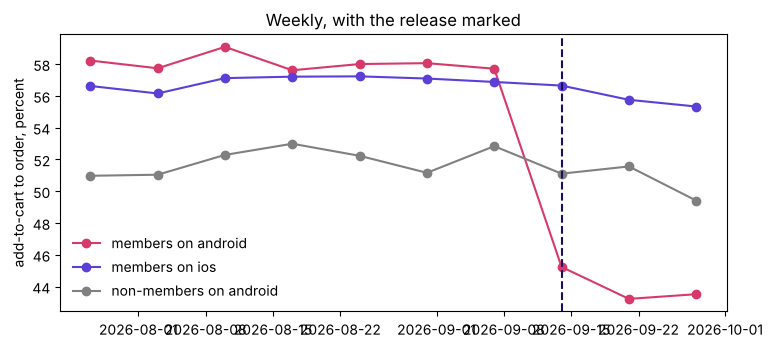

PASS  members on Android: 58 before, 44 after
PASS  members on iOS: 57 before, 56 after
PASS  non-members on Android: 52 before, 51 after


In [8]:
# The weekly view: the members' Android line breaks in the release week and no other line does.
flow["week"] = flow["event_ts"].dt.to_period("W-SUN").dt.start_time
fig, ax = plt.subplots(figsize=(8.6, 3.6))
for (m, p), colour in [((True, "android"), "#D63A6A"), ((True, "ios"), "#5B3FD6"), ((False, "android"), "grey")]:
    g = flow[(flow["is_member"] == m) & (flow["platform"] == p)].groupby(["week", "stage"]).size().unstack()
    ax.plot(g.index, 100 * g["order_placed"] / g["add_to_cart"], marker="o", color=colour,
            label=("members" if m else "non-members") + " on " + p)
ax.axvline(pd.Timestamp("2026-09-14"), ls="--", color="#1A0F5C"); ax.legend(frameon=False)
ax.set_ylabel("add-to-cart to order, percent"); ax.set_title("Weekly, with the release marked"); plt.show()
check("members on Android: 58 before, 44 after", [round(100 * v) for v in rate.loc[(True, "android")]] == [58, 44])
check("members on iOS: 57 before, 56 after", [round(100 * v) for v in rate.loc[(True, "ios")]] == [57, 56])
check("non-members on Android: 52 before, 51 after", [round(100 * v) for v in rate.loc[(False, "android")]] == [52, 51])

**What happened.** The answer is c. Members on Android fell from 58 to 44 percent, in the release
week and not before; members on iOS held at 57 to 56, and non-members on Android at 52 to 51.
**The plausible wrong answer** is "the drop is at add-to-cart to order for everyone, so the whole
checkout flow is broken". The split by membership, platform and date puts it in one place, so
the app team is right that the stage works everywhere else.

## Which step inside the checkout changed, and how many orders a week does it cost?

Add-to-cart to order has two steps inside it: starting checkout, and completing the order once
checkout has started.

orders a week not placed after the release: about 1,317
PASS  starting checkout held at 80 percent; completing it fell


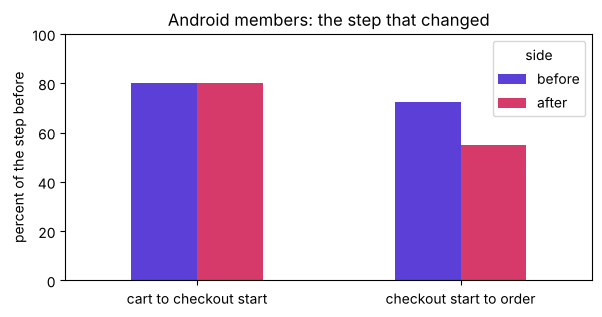

,cart to checkout start,checkout start to order
side,,
before,80.0,72.5
after,80.0,55.0


In [9]:
# Android members, the two steps inside the checkout, before and after the release.
andm = ev[ev["is_member"] & (ev["platform"] == "android")].copy()
andm["side"] = (andm["event_ts"] >= "2026-09-14").map({False: "before", True: "after"})
n = andm.groupby(["side", "stage"]).size().unstack().loc[["before", "after"]]
inside = pd.DataFrame({"cart to checkout start": n["checkout_start"] / n["add_to_cart"],
                       "checkout start to order": n["order_placed"] / n["checkout_start"]})
fall = rate.loc[(True, "android"), "before"] - rate.loc[(True, "android"), "after"]
lost_per_week = fall * n.loc["after", "add_to_cart"] / (17 / 7)
print(f"orders a week not placed after the release: about {lost_per_week:,.0f}")
check("starting checkout held at 80 percent; completing it fell", abs(inside.iloc[0, 0] - inside.iloc[1, 0]) < 0.01
      and inside.iloc[0, 1] - inside.iloc[1, 1] > 0.15)
ax = (100 * inside.T).plot.bar(figsize=(6.8, 3.2), color=["#5B3FD6", "#D63A6A"], rot=0)
ax.set_ylabel("percent of the step before"); ax.set_ylim(0, 100)
ax.set_title("Android members: the step that changed"); plt.show()
(100 * inside).round(1)

**What happened.** Starting checkout held at 80 percent; completing an order once checkout had
started fell from 72.5 to 55 percent. The loss sits in the last step of the new Android checkout,
for members only, since non-members on Android held. That points at something in the new flow
that only members see, which the app team can check. Android members added to a cart 22,841
times in the 17 days after the release; at the old rate of 58 percent, about 1,317 more orders a
week would have been placed. At an order value of Rs 400, an assumption anywhere from Rs 300 to
Rs 500, that is about Rs 5.3 lakh of orders a week (Rs 4.0 to 6.6 lakh).

**The questions, answered.** (1) Per session, the steps read 68, 118, 34, 80 and 64 percent.
(2) Search to menu view reads 118 because the carousel skips search; among sessions that
searched it reads 89. (3) Per session asks how often a menu visit becomes a cart (34 percent);
per member asks how many browsing members ever added to a cart (61 percent). (4) The fall
belongs to members on Android, 58 to 44 percent, from the release week. (5) The step that
changed is checkout start to order placed, 72.5 to 55 percent, about 1,317 orders a week.